# Concrete Strength Prediction Using Multiple Linear Regression

## Project Overview

Concrete is widely used in construction, and its compressive strength is an important property when evaluating a concrete mixture. This project explores how the quantities of different concrete ingredients and the concrete's curing age relate to its compressive strength.

Using the **Concrete Compressive Strength dataset** from the UCI Machine Learning Repository, we will build a Multiple Linear Regression model to predict compressive strength from several input variables.

### Problem Statement

Can we estimate concrete compressive strength using the mixture's ingredient quantities and curing age?

### Dataset at a Glance

- **Observations:** 1,030
- **Columns:** 9
- **Input features:** 8
- **Target variable:** Concrete compressive strength
- **Target unit:** Megapascals (MPa)
- **Learning task:** Supervised regression

### Features Used

The input variables describe the concrete mixture and its age:

- Cement
- Blast Furnace Slag
- Fly Ash
- Water
- Superplasticizer
- Coarse Aggregate
- Fine Aggregate
- Age (days)

The target variable, **concrete compressive strength (MPa)**, represents the measured strength that the model will learn to predict.

### Project Approach

We will first inspect the dataset and understand its structure, feature distributions, data quality, and relationships between variables. We will then establish a baseline, train a Multiple Linear Regression model, and evaluate its predictions on unseen test data.

Model performance will be assessed using **Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R²**. We will also examine residuals to understand where the model makes prediction errors.

### Learning Objectives

- Understand a real-world regression problem.
- Explore relationships among multiple numerical features.
- Learn how a regression model combines several predictors.
- Evaluate predictions using appropriate regression metrics.
- Identify model limitations and communicate findings honestly.

**Dataset source:** UCI Machine Learning Repository — [Concrete Compressive Strength](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength)

*This project is an educational machine learning exercise. Predictions are for learning and analysis, not for certifying concrete safety or structural suitability.*

In [1]:
import pandas as pd

df = pd.read_excel("../data/Concrete_Data.xls")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1030, 9)


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


## 2. Column Names and Feature Understanding

The dataset contains eight input features describing concrete ingredients and curing age, along with one target variable representing measured compressive strength.

The original column names include component numbers and measurement units. For readability, we will rename the columns using lowercase snake_case names.

The original dataset remains unchanged; renaming is performed only on the DataFrame in memory.

In [2]:
# Keep the original column names for reference
original_columns = df.columns.tolist()

# Create shorter, readable column names
clean_names = [
    "cement",
    "blast_furnace_slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
    "age_days",
    "concrete_strength_mpa"
]

# Check before renaming
assert len(df.columns) == len(clean_names), "Column count does not match!"

# Rename columns in the DataFrame
df = df.copy()
df.columns = clean_names

print("Dataset shape:", df.shape)
print("\nClean column names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (1030, 9)

Clean column names:
['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age_days', 'concrete_strength_mpa']


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age_days,concrete_strength_mpa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [3]:
# Check data types and non-null counts
df.info()

# Check missing values
print("\nMissing values per column:")
display(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Summary statistics
display(df.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   cement                 1030 non-null   float64
 1   blast_furnace_slag     1030 non-null   float64
 2   fly_ash                1030 non-null   float64
 3   water                  1030 non-null   float64
 4   superplasticizer       1030 non-null   float64
 5   coarse_aggregate       1030 non-null   float64
 6   fine_aggregate         1030 non-null   float64
 7   age_days               1030 non-null   int64  
 8   concrete_strength_mpa  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB

Missing values per column:


cement                   0
blast_furnace_slag       0
fly_ash                  0
water                    0
superplasticizer         0
coarse_aggregate         0
fine_aggregate           0
age_days                 0
concrete_strength_mpa    0
dtype: int64


Duplicate rows: 25


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.165631,104.507142,102.000000,192.375000,272.900000,350.000000,540.000000
blast_furnace_slag,1030.0,73.895485,86.279104,0.000000,0.000000,22.000000,142.950000,359.400000
fly_ash,1030.0,54.187136,63.996469,0.000000,0.000000,0.000000,118.270000,200.100000
water,1030.0,181.566359,21.355567,121.750000,164.900000,185.000000,192.000000,247.000000
superplasticizer,1030.0,6.203112,5.973492,0.000000,0.000000,6.350000,10.160000,32.200000
coarse_aggregate,1030.0,972.918592,77.753818,801.000000,932.000000,968.000000,1029.400000,1145.000000
fine_aggregate,1030.0,773.578883,80.175427,594.000000,730.950000,779.510000,824.000000,992.600000
age_days,1030.0,45.662136,63.169912,1.000000,7.000000,28.000000,56.000000,365.000000
concrete_strength_mpa,1030.0,35.817836,16.705679,2.331808,23.707115,34.442774,46.136287,82.599225


## 3. Data Quality Assessment

The dataset contains **1,030 observations and 9 numerical columns**, including eight input features and one continuous target variable.

### Key Findings

- **Missing values:** No missing values were detected in any column.
- **Data types:** All variables are numerical, making them suitable for an initial regression analysis without categorical encoding.
- **Duplicate records:** The dataset contains 25 exact duplicate rows. These will be investigated before deciding whether any records should be removed.
- **Target variable:** Concrete compressive strength ranges from approximately 2.33 MPa to 82.60 MPa, with a mean of 35.82 MPa.

### Data Quality Decision

No missing-value treatment is currently required. Duplicate records will be examined before any removal, because repeated measurements or identical feature combinations should not be discarded without considering the dataset's context.

In [4]:
# Identify exact duplicate rows
duplicate_rows = df[df.duplicated(keep=False)]

print("Rows involved in duplicate groups:", len(duplicate_rows))

display(
    duplicate_rows
    .sort_values(by=df.columns.tolist())
    .head(10)
)

Rows involved in duplicate groups: 36


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age_days,concrete_strength_mpa
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.298713


In [5]:
# Count rows that would remain after removing exact duplicates
print("Original rows:", len(df))
print("Unique rows:", len(df.drop_duplicates()))
print("Duplicate rows beyond first occurrences:", df.duplicated().sum())

Original rows: 1030
Unique rows: 1005
Duplicate rows beyond first occurrences: 25


### Duplicate Record Investigation

The dataset contains 25 duplicate rows beyond the first occurrence of each exact record. These represent approximately 2.43% of the original dataset.

Duplicate removal will not be performed automatically. Since repeated records can affect the weighting of observations and the reliability of model evaluation, model performance will be compared with and without exact duplicates using a consistent evaluation strategy. The possibility of duplicate observations appearing across training and test sets will also be considered.

## 4. Exploratory Data Analysis

Exploratory Data Analysis (EDA) helps us understand the distribution, variability, and potential anomalies in the dataset before model development.

In this section, we will examine the distributions of the eight input features and the target variable. This will help identify patterns that may influence the modelling process and guide further investigation.

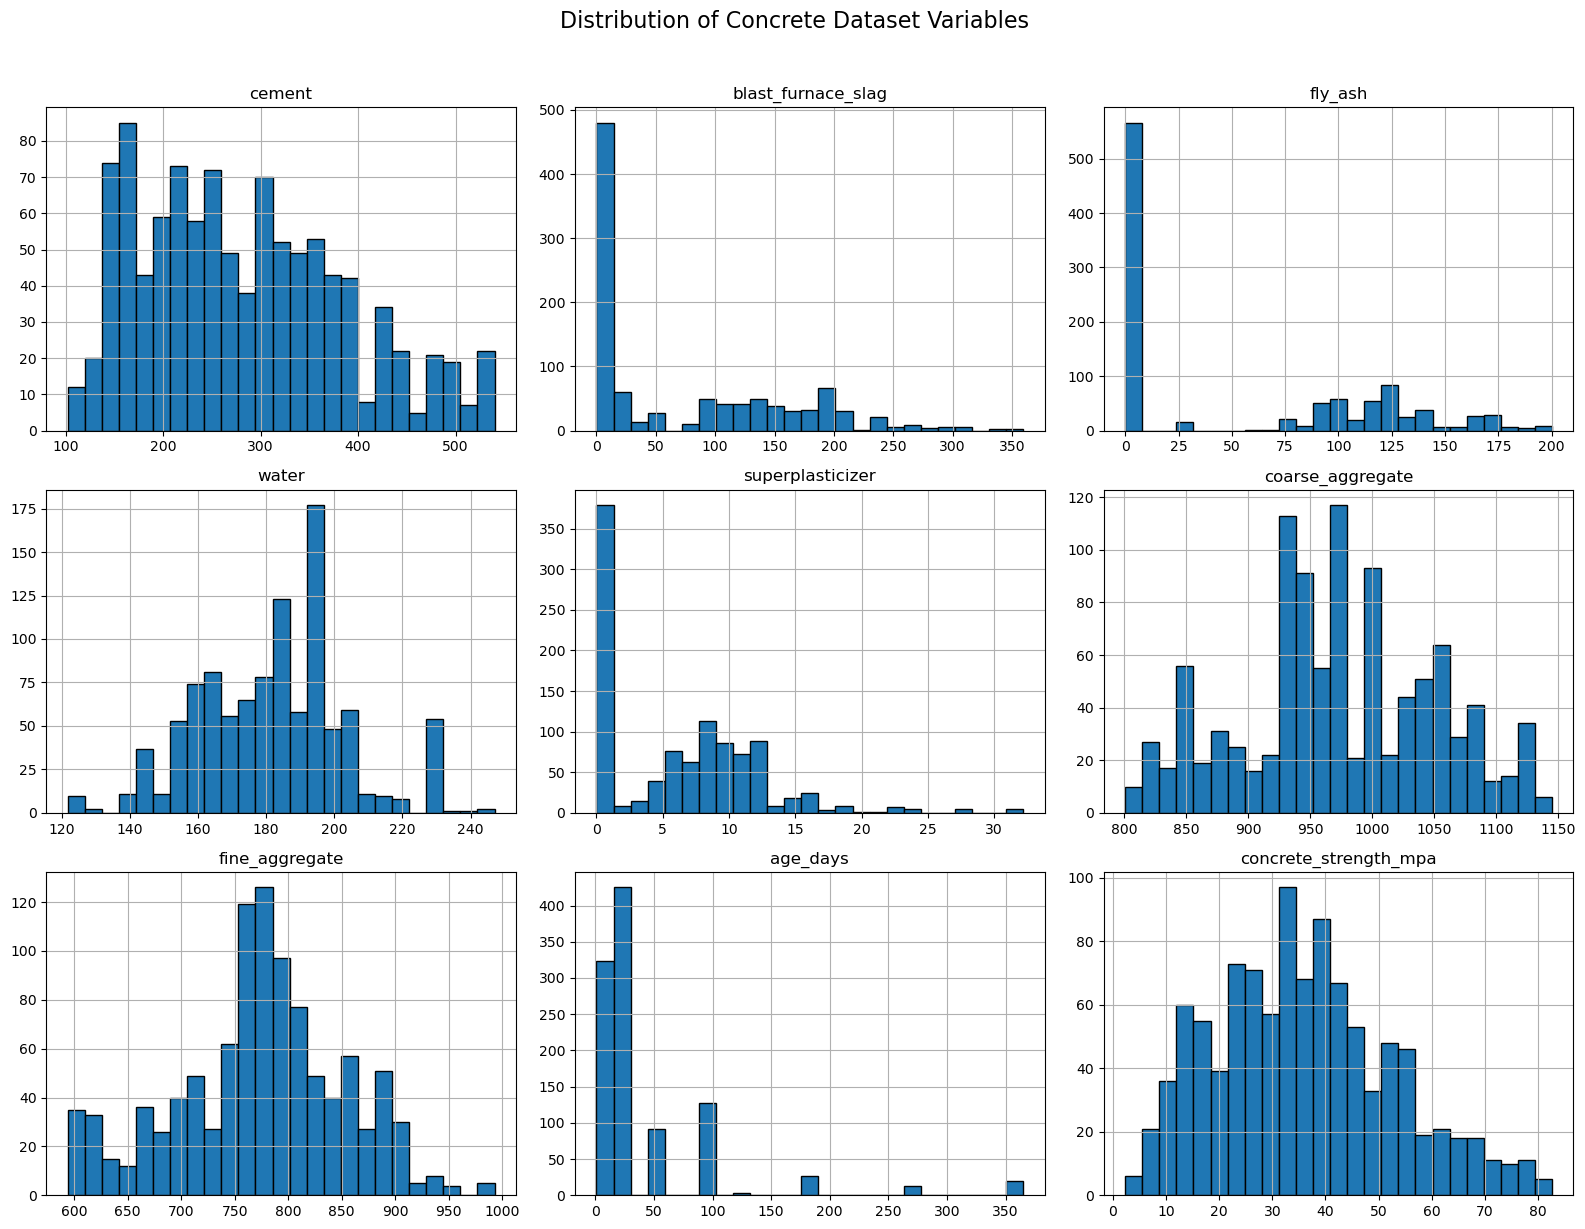

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select all numerical columns
numeric_columns = df.select_dtypes(include="number").columns

# Plot distributions
df[numeric_columns].hist(
    figsize=(16, 12),
    bins=25,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Concrete Dataset Variables",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

### Distribution Analysis — Initial Observations

The histograms reveal that the input features have different distribution patterns.

- **Cement:** Values are spread across a broad range rather than forming a perfectly symmetric distribution.
- **Blast furnace slag and fly ash:** Both variables contain many zero values, indicating that these ingredients are absent from numerous mixtures.
- **Water:** Most observations are concentrated within a relatively narrower range, with some values outside the main concentration.
- **Superplasticizer:** Many observations are zero, while non-zero quantities vary across the dataset.
- **Coarse and fine aggregates:** Both features show variation across their observed ranges, with multiple peaks in their histograms.
- **Age:** Observations are concentrated at lower curing ages, with fewer records at longer ages.
- **Concrete compressive strength:** The target varies substantially, covering low-strength and high-strength observations.

These plots describe individual variables only. They do not establish whether a particular ingredient increases or decreases concrete strength. Relationships between the input features and the target will be investigated in the next stage.

## 5. Correlation Analysis

Correlation analysis examines the strength and direction of linear relationships between numerical variables. A correlation heatmap provides a visual summary of these relationships and helps identify patterns that may be useful for regression modelling.

The analysis will focus particularly on how each input feature is correlated with concrete compressive strength. Correlation alone does not establish causation or determine the importance of a feature in a multiple regression model.

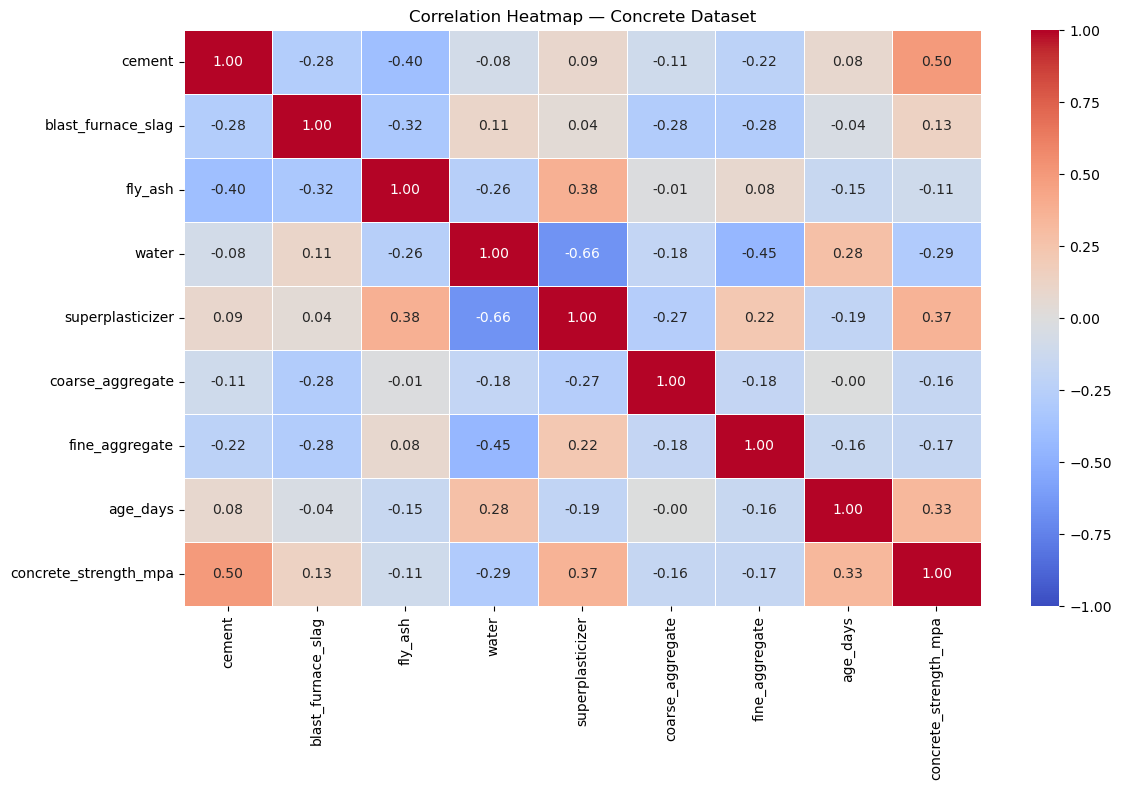

In [16]:
# Calculate pairwise Pearson correlation coefficients
correlation_matrix = df.corr(method="pearson")

# Visualize the correlation matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap — Concrete Dataset")
plt.tight_layout()
plt.show()

## 6. Feature–Target Relationship Analysis

The correlation heatmap summarizes linear relationships numerically. Scatter plots provide a visual way to investigate how individual input features relate to concrete compressive strength.

In this section, we will examine selected features against the target variable, `concrete_strength_mpa`, to look for trends, variability, and potential non-linear patterns.

These visual relationships are exploratory and do not establish causation.

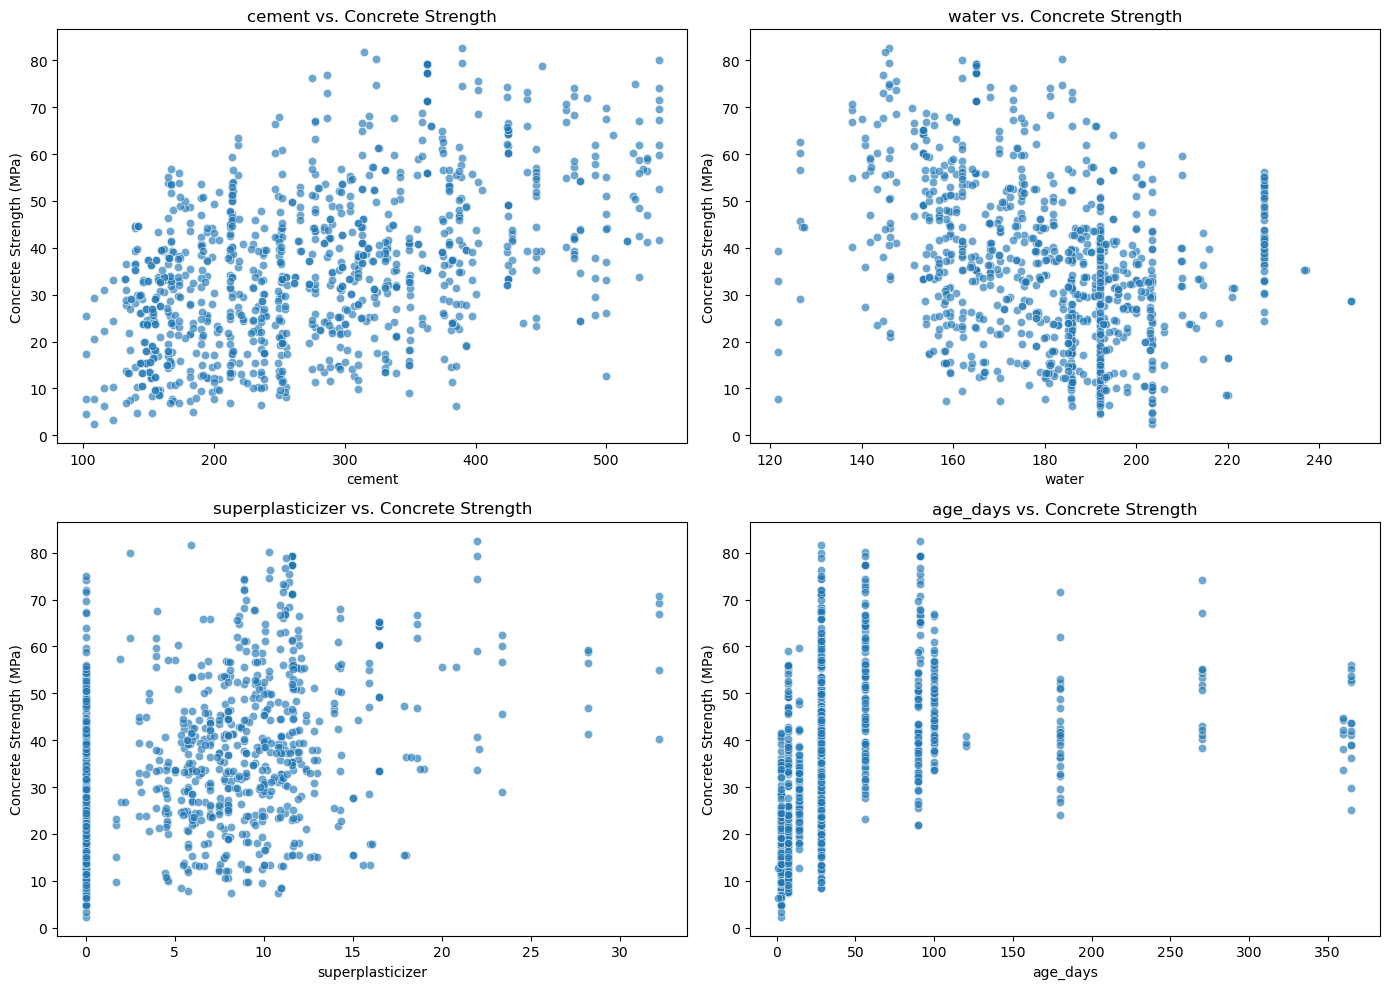

In [17]:
# Features selected for initial relationship analysis
selected_features = [
    "cement",
    "water",
    "superplasticizer",
    "age_days"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feature in zip(axes.flatten(), selected_features):
    sns.scatterplot(
        data=df,
        x=feature,
        y="concrete_strength_mpa",
        alpha=0.65,
        ax=ax
    )

    ax.set_title(f"{feature} vs. Concrete Strength")
    ax.set_xlabel(feature)
    ax.set_ylabel("Concrete Strength (MPa)")

plt.tight_layout()
plt.show()

## 7. Feature and Target Definition

For this regression task, the eight concrete mixture variables and curing age will be used as input features (`X`). The concrete compressive strength, measured in MPa, will be the target variable (`y`).

All eight input features will be retained for the initial model. Feature selection will be considered later, based on model evaluation and further analysis.

In [18]:
# Define input features (X) and target (y)

X = df.drop(columns=["concrete_strength_mpa"])
y = df["concrete_strength_mpa"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput feature names:")
print(X.columns.tolist())

Input features shape: (1030, 8)
Target shape: (1030,)

Input feature names:
['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age_days']


## 8. Train-Test Split

The dataset will be divided into training and testing subsets using an 80:20 ratio.

The training subset will be used to fit the regression model, while the test subset will be held out to evaluate its predictive performance on observations not used during training.

A fixed random state will be used to make the split reproducible.

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (824, 8)
X_test shape: (206, 8)
y_train shape: (824,)
y_test shape: (206,)


In [20]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create a simple baseline model
baseline_model = DummyRegressor(strategy="mean")

# Learn the average strength from training data only
baseline_model.fit(X_train, y_train)

# Predict strength for the unseen test data
baseline_predictions = baseline_model.predict(X_test)

# Evaluate baseline predictions
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))
print("Baseline R²:", round(baseline_r2, 3))
print("First 5 baseline predictions:", baseline_predictions[:5])


Baseline MAE: 13.052
Baseline RMSE: 16.054
Baseline R²: -0.0
First 5 baseline predictions: [35.85771807 35.85771807 35.85771807 35.85771807 35.85771807]


In [21]:
from sklearn.linear_model import LinearRegression

# Create the Multiple Linear Regression model
mlr_model = LinearRegression()

# Learn coefficients from the training data
mlr_model.fit(X_train, y_train)

# Predict strength for the unseen test data
mlr_predictions = mlr_model.predict(X_test)

print("First 5 actual strengths:")
print(y_test.head().round(2).to_list())

print("\nFirst 5 predicted strengths:")
print(mlr_predictions[:5].round(2))


First 5 actual strengths:
[52.91, 55.9, 74.5, 35.3, 10.54]

First 5 predicted strengths:
[59.66 52.04 63.52 51.57 17.22]


In [22]:
# Evaluate Multiple Linear Regression on the test data
mlr_mae = mean_absolute_error(y_test, mlr_predictions)

mlr_rmse = np.sqrt(
    mean_squared_error(y_test, mlr_predictions)
)

mlr_r2 = r2_score(y_test, mlr_predictions)

print("Multiple Linear Regression Results")
print("----------------------------------")
print("MAE:", round(mlr_mae, 3))
print("RMSE:", round(mlr_rmse, 3))
print("R²:", round(mlr_r2, 3))


Multiple Linear Regression Results
----------------------------------
MAE: 7.745
RMSE: 9.797
R²: 0.628


- MAE: How far off are predictions on average? Lower is better.
- RMSE: How strongly do large prediction errors affect the score? Lower is better.
- R²: How well does the model predict compared with a constant-mean benchmark? Higher is better; a negative value means worse performance than that benchmark.

In [23]:
import pandas as pd

coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": mlr_model.coef_
})

print("Intercept:", round(mlr_model.intercept_, 3))
print("\nLearned coefficients:")
print(
    coefficients
    .sort_values(by="Coefficient", ascending=False)
    .round(3)
    .to_string(index=False)
)


Intercept: -28.636

Learned coefficients:
           Feature  Coefficient
  superplasticizer        0.309
            cement        0.119
          age_days        0.116
blast_furnace_slag        0.109
           fly_ash        0.082
    fine_aggregate        0.024
  coarse_aggregate        0.018
             water       -0.136


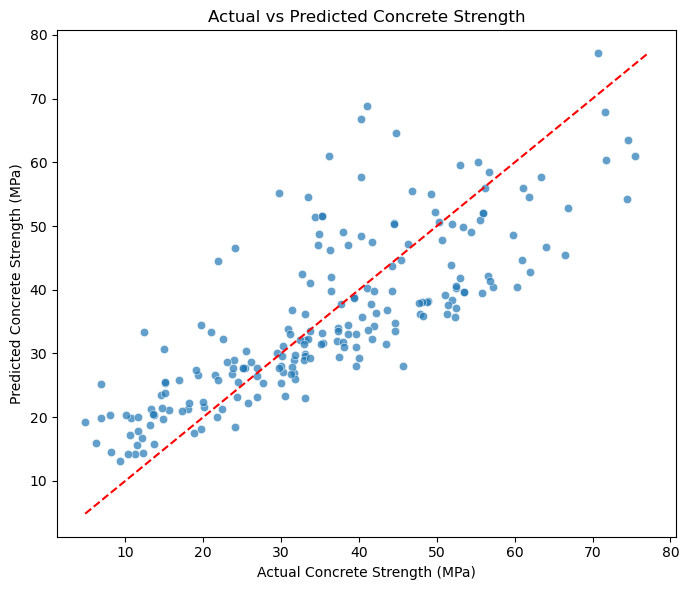

Mean residual: 0.018
Largest absolute residual: 27.78


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate prediction errors
residuals = y_test.to_numpy() - mlr_predictions

# Plot actual vs predicted values
plt.figure(figsize=(7, 6))
sns.scatterplot(
    x=y_test,
    y=mlr_predictions,
    alpha=0.7
)

# Ideal predictions lie on this diagonal
lower = min(y_test.min(), mlr_predictions.min())
upper = max(y_test.max(), mlr_predictions.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    color="red"
)

plt.xlabel("Actual Concrete Strength (MPa)")
plt.ylabel("Predicted Concrete Strength (MPa)")
plt.title("Actual vs Predicted Concrete Strength")
plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 3))
print("Largest absolute residual:", round(abs(residuals).max(), 3))


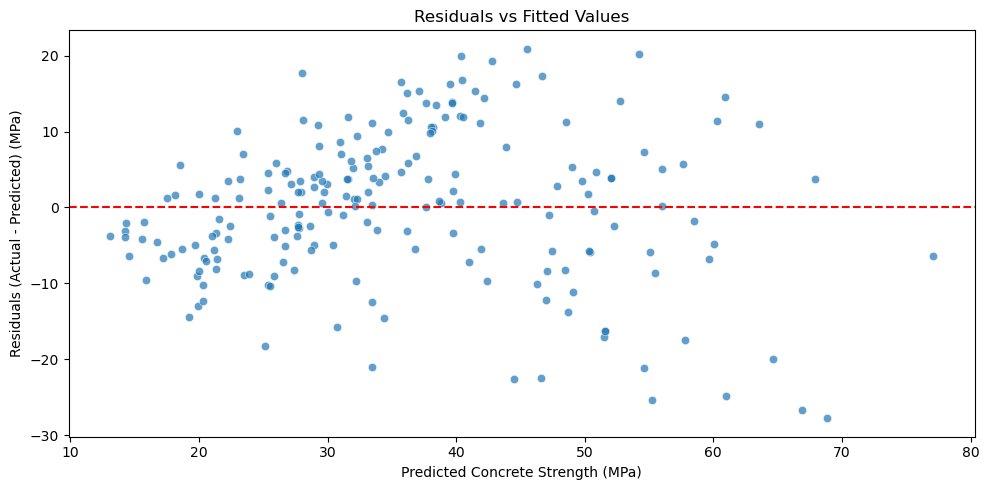

In [27]:

# Calculate residuals and fitted (predicted) values
residuals = y_test.to_numpy() - mlr_predictions
fitted_values = mlr_predictions

plt.figure(figsize=(10, 5))

sns.scatterplot(
    x=fitted_values,
    y=residuals,
    alpha=0.7
)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Concrete Strength (MPa)")
plt.ylabel("Residuals (Actual - Predicted) (MPa)")
plt.title("Residuals vs Fitted Values")
plt.tight_layout()
plt.show()


## Model Evaluation and Residual Analysis

### Model Performance

Multiple Linear Regression was evaluated on 206 observations that were not used during model training.

| Metric | Mean Baseline | Multiple Linear Regression |
|---|---:|---:|
| MAE (MPa) | 13.052 | 7.745 |
| RMSE (MPa) | 16.054 | 9.797 |
| R² | Approximately 0.000 | 0.628 |

The regression model reduced the Mean Absolute Error by approximately 40.7% compared with the mean baseline. Its lower MAE and RMSE indicate improved predictive performance on the test set.

The test R² of 0.628 indicates that the model explains approximately 62.8% of the observed variation in concrete compressive strength relative to a test-set mean benchmark.

### Residual Analysis

The residuals-versus-fitted plot shows that residual spread is not obviously constant across all fitted values. Some observations have large residuals, particularly at higher predicted strengths.

This visual pattern raises a concern about the constant-variance assumption and may also indicate that a linear model does not fully capture the relationships in the data. Further diagnostic analysis would be required before drawing a firm conclusion.

### Limitations

The model's predictions contain errors, and the residual plot suggests that performance may vary across strength ranges. The results should be treated as an educational modeling exercise, not as a substitute for laboratory testing or engineering validation.

In [28]:
error_analysis = pd.DataFrame({
    "Actual_Strength": y_test.to_numpy(),
    "Predicted_Strength": mlr_predictions,
    "Residual": residuals,
    "Absolute_Error": np.abs(residuals)
})

largest_errors = error_analysis.sort_values(
    by="Absolute_Error",
    ascending=False
).head(10)

print(largest_errors.round(2).to_string(index=False))


 Actual_Strength  Predicted_Strength  Residual  Absolute_Error
           41.05               68.83    -27.78           27.78
           40.20               66.87    -26.67           26.67
           29.79               55.21    -25.43           25.43
           36.15               60.97    -24.82           24.82
           21.92               44.47    -22.55           22.55
           24.10               46.63    -22.53           22.53
           33.40               54.59    -21.19           21.19
           12.37               33.43    -21.06           21.06
           66.42               45.53     20.90           20.90
           74.36               54.20     20.17           20.17


## Key Findings

1. The dataset contains 1,030 concrete mixture observations, eight numerical input features, and one continuous target: compressive strength in MPa.
2. Multiple Linear Regression achieved a test MAE of 7.745 MPa, RMSE of 9.797 MPa, and R² of 0.628.
3. Compared with the mean baseline, the model reduced MAE by approximately 40.7%, showing that the input features provide useful predictive information.
4. Residual analysis revealed some substantial prediction errors. The largest absolute error in the test set was 27.78 MPa.
5. The residuals-versus-fitted plot suggests that error variability may not be constant across the prediction range. This requires further investigation rather than a definitive conclusion.

## Conclusion

Multiple Linear Regression provided a meaningful first predictive model for estimating concrete compressive strength from mixture ingredients and curing age. However, its performance is imperfect, and some predictions have substantial errors. Further diagnostic analysis and comparison with other regression approaches may help determine whether the model can be improved.

These results are educational and should not be used alone to make construction safety decisions.